
# 01 — Exploratory Data Analysis (EDA)

## Objective

This notebook examines the LendingClub loan dataset to understand its structure, data quality, feature availability, distributions, and relationships before model development.

The selected cohort contains **869,540 loans and 146 columns**, covering 2013–2016 with 36-month loan terms.

The analysis focuses on:

- Identifying missing values and data-quality issues.
- Classifying features and preventing target leakage.
- Investigating feature availability across years.
- Analyzing numerical distributions, skewness, and outliers.
- Examining categorical variables and feature redundancy.
- Finalizing the feature inventory for preprocessing.

Feature-selection decisions are documented without modifying the original dataset.


## 01.1 — Initial Column Review

We begin by examining all columns in the selected cohort.

We want to identify:
- Columns with little or no available information.
- Columns with substantial missingness.
- Special missing-value codes such as -1.
- Which columns require further investigation.


In [2]:
from pathlib import Path

import pandas as pd
import polars as pl
import pyarrow.parquet as pq
from IPython.display import display

ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

COHORT_PATH = ROOT / "data/interim/lendingclub_2013_2016_36m_raw.parquet"

df = pl.scan_parquet(COHORT_PATH)

schema = df.collect_schema()
columns = schema.names()

metadata = pq.ParquetFile(COHORT_PATH).metadata
n_rows = metadata.num_rows

print(f"Rows: {n_rows:,}")
print(f"Columns: {len(columns)}")


Rows: 869,540
Columns: 146


In [3]:
# 01.1 — Column-wise missingness analysis

missing_tokens = {"", "nan", "null", "none", "n/a", "na"}
minus_one_tokens = {"-1", "-1.0"}

records = []

BATCH_SIZE = 20

for start in range(0, len(columns), BATCH_SIZE):

    batch = columns[start:start + BATCH_SIZE]
    expressions = []

    for i, col in enumerate(batch):

        x = pl.col(col)
        dtype = schema[col]

        if dtype == pl.String:
            text = x.str.strip_chars()

            missing = (
                x.is_null()
                | text.str.to_lowercase().is_in(missing_tokens)
            ).fill_null(False)

            minus_one = (
                text.is_in(minus_one_tokens)
            ).fill_null(False)

        elif dtype.is_numeric():
            missing = x.is_null()

            if dtype in (pl.Float32, pl.Float64):
                missing = (
                    missing | x.is_nan()
                ).fill_null(False)

            minus_one = (x == -1).fill_null(False)

        else:
            missing = x.is_null()
            minus_one = pl.lit(False)

        expressions.extend([
            missing.sum().alias(f"missing_{i}"),
            minus_one.sum().alias(f"minus_one_{i}")
        ])

    # Process only this batch of columns
    result = (
        df.select(expressions)
        .collect()
        .row(0, named=True)
    )

    for i, col in enumerate(batch):

        missing_count = result[f"missing_{i}"]
        minus_one_count = result[f"minus_one_{i}"]

        records.append({
            "feature": col,
            "storage_dtype": str(schema[col]),
            "missing_count": missing_count,
            "missing_pct": 100 * missing_count / n_rows,
            "minus_one_count": minus_one_count,
            "minus_one_pct": 100 * minus_one_count / n_rows,
            "coverage_pct": 100 * (n_rows - missing_count) / n_rows
        })


column_audit = pd.DataFrame(records)

column_audit = column_audit.sort_values(
    "missing_pct",
    ascending=False
).reset_index(drop=True)

# Display summary
print("Total columns:", len(column_audit))

print(
    "Completely missing:",
    (column_audit["missing_count"] == n_rows).sum()
)

print(
    "More than 90% missing:",
    (column_audit["missing_pct"] > 90).sum()
)

print(
    "Columns containing -1:",
    (column_audit["minus_one_count"] > 0).sum()
)

print("\nMissingness report:")

display(column_audit.round(2))

Total columns: 146
Completely missing: 13
More than 90% missing: 30
Columns containing -1: 1

Missingness report:


,feature,storage_dtype,missing_count,missing_pct,minus_one_count,minus_one_pct,coverage_pct
0,sec_app_num_rev_accts,String,869540,100.0,0,0.0,0.0
1,next_pymnt_d,String,869540,100.0,0,0.0,0.0
2,sec_app_earliest_cr_line,String,869540,100.0,0,0.0,0.0
3,sec_app_fico_range_high,String,869540,100.0,0,0.0,0.0
4,sec_app_fico_range_low,String,869540,100.0,0,0.0,0.0
...,...,...,...,...,...,...,...
141,debt_settlement_flag,String,0,0.0,0,0.0,100.0
142,issue_date,Date,0,0.0,0,0.0,100.0
143,term_months,Int16,0,0.0,0,0.0,100.0
144,issue_year,Int32,0,0.0,0,0.0,100.0


In [4]:
# Initial feature screening using missingness

screening = column_audit.copy()

def screen_feature(row):
    feature = row["feature"]
    missing_pct = row["missing_pct"]

    if row["missing_count"] == n_rows:
        return "SKIP_ALL_MISSING"

    if feature.startswith("hardship_") or feature in {
        "deferral_term",
        "payment_plan_start_date",
        "orig_projected_additional_accrued_interest",
    }:
        return "SKIP_POST_LOAN"

    if missing_pct > 80:
        return "SKIP_HIGH_MISSING"

    return "REVIEW_FURTHER"


screening["screen_status"] = screening.apply(
    screen_feature, axis=1
)

# Display summary
display(
    screening["screen_status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="columns")
)

# Columns to investigate further
remaining_columns = screening.loc[
    screening["screen_status"] == "REVIEW_FURTHER",
    "feature"
].tolist()

# Columns skipped at this stage
skipped_columns = screening.loc[
    screening["screen_status"] != "REVIEW_FURTHER",
    ["feature", "missing_pct", "screen_status"]
]

print("Remaining columns:", len(remaining_columns))
print("Skipped columns:", len(skipped_columns))
pd.set_option("display.max_rows", 200)
display(skipped_columns)

,status,columns
0,REVIEW_FURTHER,114
1,SKIP_POST_LOAN,15
2,SKIP_ALL_MISSING,13
3,SKIP_HIGH_MISSING,4


Remaining columns: 114
Skipped columns: 32


,feature,missing_pct,screen_status
0,sec_app_num_rev_accts,100.000000,SKIP_ALL_MISSING
1,next_pymnt_d,100.000000,SKIP_ALL_MISSING
2,sec_app_earliest_cr_line,100.000000,SKIP_ALL_MISSING
3,sec_app_fico_range_high,100.000000,SKIP_ALL_MISSING
4,sec_app_fico_range_low,100.000000,SKIP_ALL_MISSING
5,sec_app_inq_last_6mths,100.000000,SKIP_ALL_MISSING
6,sec_app_revol_util,100.000000,SKIP_ALL_MISSING
7,sec_app_open_acc,100.000000,SKIP_ALL_MISSING
8,sec_app_mort_acc,100.000000,SKIP_ALL_MISSING
9,sec_app_open_act_il,100.000000,SKIP_ALL_MISSING


### Initial Feature Screening

Our cohort contains 146 columns.

The missingness analysis identified 31 columns with more than
80% missing values. These include completely unavailable fields,
post-loan hardship information, joint-application variables, and
months since the last public record.

We will exclude these columns from detailed EDA for the primary model.

The remaining 115 columns require classification by financial
meaning, prediction-time availability, and data type.

No columns have been physically removed from the dataset.


## 01.2 — Column Classification

Most original LendingClub columns are stored as strings, so storage types alone cannot determine whether a feature is numerical or categorical.

We classify all 146 columns based on their meaning and observed values into numerical, categorical, date, identifier, text, target, or review categories.

This classification supports subsequent feature-eligibility decisions. No original columns are removed.


In [5]:
import pandas as pd
import polars as pl
from IPython.display import display

# Reuse df, schema, columns, column_audit, n_rows from 01.1

# Sample across all four years instead of just the first rows
# Derive issue year temporarily from issue_d
issue_dtype = schema["issue_d"]

if issue_dtype.is_temporal():
    year_expr = pl.col("issue_d").dt.year()
else:
    s = pl.col("issue_d").cast(pl.String).str.strip_chars()

    parsed_date = pl.coalesce(
        s.str.strptime(pl.Date, "%Y-%m-%d", strict=False),
        (s + "-01").str.strptime(pl.Date, "%b-%Y-%d", strict=False),
        (s + "-01").str.strptime(pl.Date, "%b-%y-%d", strict=False),
        (s + "-01").str.strptime(pl.Date, "%Y-%m-%d", strict=False),
    )

    year_expr = parsed_date.dt.year()

# Temporary column, not saved to the dataset
sample_base = df.with_columns(
    year_expr.alias("_eda_year")
)

sample = pl.concat([
    sample_base.filter(
        pl.col("_eda_year") == year
    ).head(750)
    for year in range(2013, 2017)
]).drop("_eda_year").collect().to_pandas()

print("Sample shape:", sample.shape)
print(sample["issue_d"].head())

# Columns whose meaning determines their type
date_cols = {
    "issue_d", "issue_date", "earliest_cr_line",
    "last_pymnt_d", "next_pymnt_d", "last_credit_pull_d",
    "hardship_start_date", "hardship_end_date",
    "payment_plan_start_date", "settlement_date",
    "debt_settlement_flag_date", "sec_app_earliest_cr_line"
}

id_cols = {"id", "member_id", "url","unnamed: 0"}

text_cols = {"emp_title", "title", "desc"}
metadata_cols = {
    "issue_year", "term_months"
}

categorical_cols = {
    "term", "emp_length", "zip_code", "addr_state",
    "grade", "sub_grade", "purpose", "home_ownership",
    "verification_status", "verification_status_joint",
    "application_type", "initial_list_status",
    "policy_code", "pymnt_plan", "hardship_flag",
    "hardship_type", "hardship_reason",
    "debt_settlement_flag", "disbursement_method"
}

target_cols = {"loan_status", "target"}

missing_tokens = {"", "nan", "null", "none", "n/a"}


def identify_type(col):
    if col in target_cols:
        return "TARGET"

    if col in date_cols:
        return "DATE"

    if col in id_cols or col.lower().startswith("unnamed:"):
        return "IDENTIFIER"

    if col in text_cols:
        return "TEXT"

    if col in categorical_cols:
        return "CATEGORICAL"

    if schema[col].is_numeric():
        return "NUMERICAL"

    if schema[col].is_temporal():
        return "DATE"

    values = sample[col].astype("string").str.strip()
    values = values[
        ~values.str.lower().isin(missing_tokens | {"-1"})
    ].dropna()

    if values.empty:
        return "REVIEW_TYPE"

    # Numeric recognition only; original values are unchanged
    cleaned = values.str.replace(r"[$,%]", "", regex=True)
    numeric = pd.to_numeric(cleaned, errors="coerce")

    numeric_fraction = numeric.notna().mean()

    if numeric_fraction >= 0.98:
        return "NUMERICAL"

    if numeric_fraction > 0.02:
        return "REVIEW_TYPE"

    return "CATEGORICAL"


feature_inventory = pd.DataFrame({
    "feature": columns,
    "data_group": [identify_type(c) for c in columns]
})

# Reuse missingness analysis from 01.1
feature_inventory = feature_inventory.merge(
    column_audit[
        ["feature", "missing_count", "missing_pct",
         "minus_one_count", "minus_one_pct"]
    ],
    on="feature",
    how="left",
    validate="one_to_one"
)

print("COLUMN GROUP COUNTS")
display(
    feature_inventory["data_group"]
    .value_counts()
    .rename_axis("group")
    .reset_index(name="columns")
)

print("\nCOLUMNS IN EACH GROUP")
for group, part in feature_inventory.groupby(
    "data_group", sort=True
):
    print(f"\n{group} ({len(part)})")
    print(", ".join(part["feature"].tolist()))

print("\nNEED MANUAL TYPE REVIEW")
display(
    feature_inventory[
        feature_inventory["data_group"] == "REVIEW_TYPE"
    ]
)

Sample shape: (3000, 146)
0    Dec-2013
1    Dec-2013
2    Dec-2013
3    Dec-2013
4    Dec-2013
Name: issue_d, dtype: object
COLUMN GROUP COUNTS


,group,columns
0,NUMERICAL,98
1,CATEGORICAL,20
2,REVIEW_TYPE,11
3,DATE,10
4,IDENTIFIER,3
5,TEXT,2
6,TARGET,2



COLUMNS IN EACH GROUP

CATEGORICAL (20)
term, grade, sub_grade, emp_length, home_ownership, verification_status, pymnt_plan, purpose, zip_code, addr_state, initial_list_status, policy_code, application_type, verification_status_joint, hardship_flag, hardship_type, hardship_reason, hardship_status, hardship_loan_status, debt_settlement_flag

DATE (10)
issue_d, earliest_cr_line, last_pymnt_d, next_pymnt_d, last_credit_pull_d, sec_app_earliest_cr_line, hardship_start_date, hardship_end_date, payment_plan_start_date, issue_date

IDENTIFIER (3)
Unnamed: 0, id, url

NUMERICAL (98)
loan_amnt, funded_amnt, funded_amnt_inv, int_rate, installment, annual_inc, dti, delinq_2yrs, fico_range_low, fico_range_high, inq_last_6mths, mths_since_last_delinq, mths_since_last_record, open_acc, pub_rec, revol_bal, revol_util, total_acc, out_prncp, out_prncp_inv, total_pymnt, total_pymnt_inv, total_rec_prncp, total_rec_int, total_rec_late_fee, recoveries, collection_recovery_fee, last_pymnt_amnt, last_fico_r

,feature,data_group,missing_count,missing_pct,minus_one_count,minus_one_pct
114,revol_bal_joint,REVIEW_TYPE,869540,100.0,0,0.0
115,sec_app_fico_range_low,REVIEW_TYPE,869540,100.0,0,0.0
116,sec_app_fico_range_high,REVIEW_TYPE,869540,100.0,0,0.0
118,sec_app_inq_last_6mths,REVIEW_TYPE,869540,100.0,0,0.0
119,sec_app_mort_acc,REVIEW_TYPE,869540,100.0,0,0.0
120,sec_app_open_acc,REVIEW_TYPE,869540,100.0,0,0.0
121,sec_app_revol_util,REVIEW_TYPE,869540,100.0,0,0.0
122,sec_app_open_act_il,REVIEW_TYPE,869540,100.0,0,0.0
123,sec_app_num_rev_accts,REVIEW_TYPE,869540,100.0,0,0.0
124,sec_app_chargeoff_within_12_mths,REVIEW_TYPE,869540,100.0,0,0.0


In [6]:
# Screening after data-type classification
# No columns are physically removed

def assign_screen_status(row):

    if row["missing_count"] == n_rows:
        return "SKIP_ALL_MISSING"

    if row["missing_pct"] > 80:
        return "SKIP_HIGH_MISSING"

    return "REVIEW_FURTHER"


feature_inventory["screen_status"] = (
    feature_inventory.apply(assign_screen_status, axis=1)
)

print("SCREENING SUMMARY")

display(
    feature_inventory.groupby(
        ["data_group", "screen_status"]
    ).size().reset_index(name="columns")
)

print("\nSKIPPED FROM DETAILED EDA")

display(
    feature_inventory.loc[
        feature_inventory["screen_status"] != "REVIEW_FURTHER",
        ["feature", "data_group", "missing_pct", "screen_status"]
    ]
)

print("\nREMAINING FOR FURTHER REVIEW")

display(
    feature_inventory.loc[
        feature_inventory["screen_status"] == "REVIEW_FURTHER",
        ["feature", "data_group", "missing_pct"]
    ]
)

SCREENING SUMMARY


,data_group,screen_status,columns
0,CATEGORICAL,REVIEW_FURTHER,15
1,CATEGORICAL,SKIP_HIGH_MISSING,5
2,DATE,REVIEW_FURTHER,5
3,DATE,SKIP_ALL_MISSING,2
4,DATE,SKIP_HIGH_MISSING,3
5,IDENTIFIER,REVIEW_FURTHER,3
6,NUMERICAL,REVIEW_FURTHER,88
7,NUMERICAL,SKIP_HIGH_MISSING,10
8,REVIEW_TYPE,SKIP_ALL_MISSING,11
9,TARGET,REVIEW_FURTHER,2



SKIPPED FROM DETAILED EDA


,feature,data_group,missing_pct,screen_status
30,mths_since_last_record,NUMERICAL,81.707685,SKIP_HIGH_MISSING
48,next_pymnt_d,DATE,100.000000,SKIP_ALL_MISSING
56,annual_inc_joint,NUMERICAL,99.373232,SKIP_HIGH_MISSING
57,dti_joint,NUMERICAL,99.373577,SKIP_HIGH_MISSING
58,verification_status_joint,CATEGORICAL,99.373232,SKIP_HIGH_MISSING
114,revol_bal_joint,REVIEW_TYPE,100.000000,SKIP_ALL_MISSING
115,sec_app_fico_range_low,REVIEW_TYPE,100.000000,SKIP_ALL_MISSING
116,sec_app_fico_range_high,REVIEW_TYPE,100.000000,SKIP_ALL_MISSING
117,sec_app_earliest_cr_line,DATE,100.000000,SKIP_ALL_MISSING
118,sec_app_inq_last_6mths,REVIEW_TYPE,100.000000,SKIP_ALL_MISSING



REMAINING FOR FURTHER REVIEW


,feature,data_group,missing_pct
0,Unnamed: 0,IDENTIFIER,0.000000
1,id,IDENTIFIER,0.000000
2,loan_amnt,NUMERICAL,0.000000
3,funded_amnt,NUMERICAL,0.000000
4,funded_amnt_inv,NUMERICAL,0.000000
5,term,CATEGORICAL,0.000000
6,int_rate,NUMERICAL,0.000000
7,installment,NUMERICAL,0.000000
8,grade,CATEGORICAL,0.000000
9,sub_grade,CATEGORICAL,0.000000



## 01.3 — Feature Eligibility and Leakage Screening

We evaluate features based on:

- **Target leakage:** Exclude information recorded after loan issuance or during repayment.
- **Identifiers:** Exclude variables that uniquely identify individual loans.
- **Missingness:** Flag features with insufficient information.
- **Prediction-time availability:** Separate lender-generated information for further review.
- **Metadata:** Retain date and cohort information for analysis without treating it as a predictor.

The objective is to identify features suitable for further EDA and modeling.

Final feature decisions will also consider historical availability, redundancy, and preprocessing requirements.



In [7]:
# 01.3 — Feature eligibility screening

# Fields containing information about loan performance after issuance
post_loan = {
    "out_prncp", "out_prncp_inv",
    "total_pymnt", "total_pymnt_inv",
    "total_rec_prncp", "total_rec_int",
    "total_rec_late_fee", "recoveries",
    "collection_recovery_fee",
    "last_pymnt_d", "last_pymnt_amnt",
    "next_pymnt_d", "last_credit_pull_d",
    "last_fico_range_low", "last_fico_range_high",
    "pymnt_plan", "payment_plan_start_date",
    "debt_settlement_flag", "deferral_term",
    "orig_projected_additional_accrued_interest"
}

# LendingClub's pricing/funding decisions
lender_info = {
    "funded_amnt", "funded_amnt_inv",
    "int_rate", "installment",
    "grade", "sub_grade",
    "initial_list_status"
}

# Columns for cohort tracking, not predictive EDA
metadata_cols = {
    "issue_d", "issue_date",
    "issue_year", "term", "term_months",
    "policy_code"
}


def eligibility(row):
    col = row["feature"]

    if col in {"loan_status", "target"}:
        return "TARGET"

    if row["missing_pct"] == 100:
        return "SKIP_ALL_MISSING"

    if (
        col in post_loan
        or col.startswith("hardship_")
        or col.startswith("settlement_")
        or col.startswith("debt_settlement_")
    ):
        return "EXCLUDE_LEAKAGE"

    if row["data_group"] == "IDENTIFIER":
        return "EXCLUDE_IDENTIFIER"

    if col in metadata_cols:
        return "METADATA"

    if row["missing_pct"] > 80:
        return "SKIP_HIGH_MISSING"

    if col in lender_info:
        return "REVIEW_LENDER_INFO"

    return "EDA_CANDIDATE"


feature_inventory["eligibility"] = (
    feature_inventory.apply(eligibility, axis=1)
)

# Summary
display(
    feature_inventory["eligibility"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="columns")
)

# Inspect classification with reasons
display(
    feature_inventory[
        ["feature", "data_group",
         "missing_pct", "eligibility"]
    ].sort_values(["eligibility", "feature"])
)

print("\nNumerical EDA candidates:",
    len(feature_inventory[
        (feature_inventory["eligibility"] == "EDA_CANDIDATE")
        & (feature_inventory["data_group"] == "NUMERICAL")
    ])
)

print("Categorical EDA candidates:",
    len(feature_inventory[
        (feature_inventory["eligibility"] == "EDA_CANDIDATE")
        & (feature_inventory["data_group"] == "CATEGORICAL")
    ])
)

,status,columns
0,EDA_CANDIDATE,80
1,EXCLUDE_LEAKAGE,31
2,SKIP_ALL_MISSING,13
3,REVIEW_LENDER_INFO,7
4,METADATA,6
5,SKIP_HIGH_MISSING,4
6,EXCLUDE_IDENTIFIER,3
7,TARGET,2


,feature,data_group,missing_pct,eligibility
59,acc_now_delinq,NUMERICAL,0.000000,EDA_CANDIDATE
77,acc_open_past_24mths,NUMERICAL,0.000000,EDA_CANDIDATE
22,addr_state,CATEGORICAL,0.000000,EDA_CANDIDATE
72,all_util,NUMERICAL,61.100237,EDA_CANDIDATE
13,annual_inc,NUMERICAL,0.000000,EDA_CANDIDATE
55,application_type,CATEGORICAL,0.000000,EDA_CANDIDATE
78,avg_cur_bal,NUMERICAL,0.001035,EDA_CANDIDATE
79,bc_open_to_buy,NUMERICAL,1.051705,EDA_CANDIDATE
80,bc_util,NUMERICAL,1.111622,EDA_CANDIDATE
81,chargeoff_within_12_mths,NUMERICAL,0.000000,EDA_CANDIDATE



Numerical EDA candidates: 70
Categorical EDA candidates: 7



## 01.4 — Numerical Feature Validation and Grouping

After feature eligibility screening, 70 numerical candidates remain.

Before analyzing their distributions, we validate numerical conversion, identify constant features, and examine missingness.

The features are subsequently grouped by financial meaning to support structured analysis of creditworthiness, repayment capacity, account activity, and delinquency history.

No features or observations are removed during this stage.


In [8]:
# 01.4.1 — Validate numerical candidates

numeric_cols = feature_inventory.loc[
    (feature_inventory["eligibility"] == "EDA_CANDIDATE")
    & (feature_inventory["data_group"] == "NUMERICAL"),
    "feature"
].tolist()

missing_tokens = ["", "nan", "null", "none", "n/a", "na"]

results = []

for start in range(0, len(numeric_cols), 10):

    batch = numeric_cols[start:start + 10]
    expressions = []

    for col in batch:
        text = (
            pl.col(col)
            .cast(pl.String)
            .str.strip_chars()
        )

        observed = (
            text.is_not_null()
            & ~text.str.to_lowercase().is_in(missing_tokens)
        ).fill_null(False)

        # Remove percentage formatting for numerical validation
        number = (
            text
            .str.replace_all("%", "")
            .cast(pl.Float64, strict=False)
            )

        valid_number = (
            pl.when(observed)
            .then(number)
            .otherwise(None)
        )

        expressions.extend([
            (
                observed & number.is_null()
            ).fill_null(False).sum().alias(f"{col}__invalid"),

            valid_number.drop_nulls()
            .n_unique().alias(f"{col}__unique"),
        ])

    values = df.select(expressions).collect().row(
        0, named=True
    )

    for col in batch:
        results.append({
            "feature": col,
            "invalid_numeric": values[f"{col}__invalid"],
            "unique_values": values[f"{col}__unique"],
        })


numeric_check = pd.DataFrame(results)

numeric_check = numeric_check.merge(
    feature_inventory[["feature", "missing_pct"]],
    on="feature",
    how="left",
    validate="one_to_one"
)

print("Numerical candidates:", len(numeric_check))

print(
    "Columns with invalid numerical values:",
    (numeric_check["invalid_numeric"] > 0).sum()
)

print(
    "Constant or empty numerical columns:",
    (numeric_check["unique_values"] <= 1).sum()
)

print("\nColumns requiring attention:")

display(
    numeric_check[
        (numeric_check["invalid_numeric"] > 0)
        | (numeric_check["unique_values"] <= 1)
    ]
)

print("\nNumerical candidates by missingness:")

display(
    numeric_check.sort_values(
        "missing_pct", ascending=False
    ).round(2)
)

Numerical candidates: 70
Columns with invalid numerical values: 0
Constant or empty numerical columns: 0

Columns requiring attention:


,feature,invalid_numeric,unique_values,missing_pct



Numerical candidates by missingness:


,feature,invalid_numeric,unique_values,missing_pct
45,mths_since_recent_bc_dlq,0,163,74.26
14,mths_since_last_major_derog,0,166,71.41
24,il_util,0,232,66.57
47,mths_since_recent_revol_delinq,0,163,64.16
22,mths_since_rcnt_il,0,331,62.31
28,all_util,0,166,61.10
31,total_cu_tl,0,52,61.10
27,max_bal_bc,0,24879,61.10
26,open_rv_24m,0,47,61.10
25,open_rv_12m,0,26,61.10



### 01.4.2 — Numerical Validation Findings and Feature Groups

The numerical validation confirmed:

- All 70 candidate features could be interpreted numerically without unexpected parsing failures.
- No candidate numerical feature was constant or entirely empty.
- Missingness varies considerably across features and requires further investigation.

For systematic analysis, the numerical features are organized into six financial groups:

1. Loan amount and repayment capacity.
2. Credit score.
3. Credit balances, limits, and utilization.
4. Account counts and composition.
5. Recent credit activity and credit-history age.
6. Delinquency and adverse credit records.

These groups help identify redundancy, missingness patterns, and potential financial relationships without automatically excluding features.


In [9]:
# 01.4.2 — Group features by financial meaning

financial_groups = {
    "Loan & repayment capacity": [
        "loan_amnt", "annual_inc", "dti"
    ],

    "Credit score": [
        "fico_range_low", "fico_range_high"
    ],

    "Balances, limits & utilization": [
        "revol_bal", "revol_util", "bc_open_to_buy",
        "bc_util", "avg_cur_bal", "tot_cur_bal",
        "total_bal_ex_mort", "total_bal_il", "max_bal_bc",
        "all_util", "il_util", "total_rev_hi_lim",
        "tot_hi_cred_lim", "total_bc_limit",
        "total_il_high_credit_limit", "percent_bc_gt_75"
    ],

    "Account counts & composition": [
        "open_acc", "total_acc", "mort_acc",
        "num_bc_sats", "num_bc_tl", "num_il_tl",
        "num_op_rev_tl", "num_rev_accts",
        "num_rev_tl_bal_gt_0", "num_sats",
        "num_actv_bc_tl", "num_actv_rev_tl",
        "open_act_il", "total_cu_tl"
    ],

    "Recent activity & credit age": [
        "inq_last_6mths", "inq_last_12m", "inq_fi",
        "acc_open_past_24mths", "open_acc_6m",
        "open_il_12m", "open_il_24m",
        "open_rv_12m", "open_rv_24m",
        "num_tl_op_past_12m", "mths_since_recent_inq",
        "mths_since_rcnt_il", "mths_since_recent_bc",
        "mo_sin_old_il_acct", "mo_sin_old_rev_tl_op",
        "mo_sin_rcnt_rev_tl_op", "mo_sin_rcnt_tl"
    ],

    "Delinquency & adverse records": [
        "delinq_2yrs", "pub_rec", "tax_liens",
        "pub_rec_bankruptcies", "collections_12_mths_ex_med",
        "chargeoff_within_12_mths", "acc_now_delinq",
        "tot_coll_amt", "delinq_amnt",
        "num_accts_ever_120_pd", "num_tl_120dpd_2m",
        "num_tl_30dpd", "num_tl_90g_dpd_24m",
        "pct_tl_nvr_dlq", "mths_since_last_delinq",
        "mths_since_last_major_derog",
        "mths_since_recent_bc_dlq",
        "mths_since_recent_revol_delinq"
    ]
}

# Create feature-to-group mapping
group_rows = [
    {"feature": feature, "financial_group": group}
    for group, features in financial_groups.items()
    for feature in features
]

group_df = pd.DataFrame(group_rows)

# Check grouping consistency
assert not group_df["feature"].duplicated().any()

numeric_cols = feature_inventory.loc[
    (feature_inventory["eligibility"] == "EDA_CANDIDATE")
    & (feature_inventory["data_group"] == "NUMERICAL"),
    "feature"
].tolist()

assert set(group_df["feature"]) == set(numeric_cols), (
    "Numerical candidates and grouped features do not match."
)

# Join with our existing missingness results
numeric_inventory = group_df.merge(
    feature_inventory[
        ["feature", "missing_pct"]
    ],
    on="feature",
    how="left",
    validate="one_to_one"
)

display(
    numeric_inventory.groupby("financial_group")
    .agg(
        features=("feature", "count"),
        high_missing=("missing_pct", lambda s: (s > 50).sum())
    )
    .reset_index()
)

,financial_group,features,high_missing
0,Account counts & composition,14,2
1,"Balances, limits & utilization",16,4
2,Credit score,2,0
3,Delinquency & adverse records,18,3
4,Loan & repayment capacity,3,0
5,Recent activity & credit age,17,8



## 01.5 — Historical Feature Availability

Feature availability must be examined across loan-origination years because the LendingClub dataset contains variables introduced at different times.

We calculate yearly coverage from 2013 to 2016 to distinguish:

- **Late-introduced features:** Variables largely unavailable during the training period.
- **Event-dependent missingness:** Variables that may be missing because no relevant credit event was recorded.
- **Consistently available features:** Variables suitable for further consideration in the primary model.

The objective is to maintain consistent feature availability during model development and reduce the risk of learning artificial patterns caused by historical data-collection changes.


In [10]:
# 01.4 — Year-wise feature availability

import pandas as pd
import polars as pl
from IPython.display import display

# Include all EDA candidates, not only numerical features
candidates = feature_inventory.loc[
    feature_inventory["eligibility"] == "EDA_CANDIDATE",
    "feature"
].tolist()

missing_tokens = ["", "nan", "null", "none", "n/a", "na"]

expressions = [pl.len().alias("loans")]

for col in candidates:

    x = pl.col(col).cast(pl.String).str.strip_chars()

    valid = (
        x.is_not_null()
        & ~x.str.to_lowercase().is_in(missing_tokens)
    ).fill_null(False)

    expressions.append(
        (100 * valid.mean()).round(2).alias(col)
    )

# Full cohort: 2013–2016
year_summary = (
    df.group_by("issue_year")
    .agg(expressions)
    .sort("issue_year")
    .collect()
    .to_pandas()
    .set_index("issue_year")
)

# Transpose: one feature per row
year_coverage = year_summary.drop(columns="loans").T

year_coverage.index.name = "feature"
year_coverage.columns = year_coverage.columns.astype(int)

year_coverage = year_coverage.merge(
    feature_inventory[
        ["feature", "data_group", "missing_pct"]
    ],
    left_index=True,
    right_on="feature",
    how="left",
    validate="one_to_one"
).set_index("feature")

# Identify features with less than 50% coverage
# in at least one development year
development_years = [2013, 2014, 2015]

year_coverage["low_development_coverage"] = (
    year_coverage[development_years]
    .lt(50)
    .any(axis=1)
)

print("Feature availability by year (%):")

display(
    year_coverage.sort_values(
        development_years
    ).round(2)
)

print("\nFeatures requiring availability review:")

display(
    year_coverage[
        year_coverage["low_development_coverage"]
    ].round(2)
)

print(
    "\nNumber requiring review:",
    year_coverage["low_development_coverage"].sum()
)

Feature availability by year (%):


,2013,2014,2015,2016,data_group,missing_pct,low_development_coverage
feature,,,,,,,
il_util,0.00,0.00,4.54,85.92,NUMERICAL,66.57,True
mths_since_rcnt_il,0.00,0.00,5.11,96.87,NUMERICAL,62.31,True
open_acc_6m,0.00,0.00,5.27,99.99,NUMERICAL,61.10,True
open_act_il,0.00,0.00,5.27,99.99,NUMERICAL,61.10,True
open_il_12m,0.00,0.00,5.27,99.99,NUMERICAL,61.10,True
open_il_24m,0.00,0.00,5.27,99.99,NUMERICAL,61.10,True
total_bal_il,0.00,0.00,5.27,99.99,NUMERICAL,61.10,True
open_rv_12m,0.00,0.00,5.27,99.99,NUMERICAL,61.10,True
open_rv_24m,0.00,0.00,5.27,99.99,NUMERICAL,61.10,True



Features requiring availability review:


,2013,2014,2015,2016,data_group,missing_pct,low_development_coverage
feature,,,,,,,
mths_since_last_delinq,43.53,51.08,52.01,53.16,NUMERICAL,48.72,True
mths_since_last_major_derog,20.49,29.25,30.20,29.36,NUMERICAL,71.41,True
open_acc_6m,0.00,0.00,5.27,99.99,NUMERICAL,61.10,True
open_act_il,0.00,0.00,5.27,99.99,NUMERICAL,61.10,True
open_il_12m,0.00,0.00,5.27,99.99,NUMERICAL,61.10,True
open_il_24m,0.00,0.00,5.27,99.99,NUMERICAL,61.10,True
mths_since_rcnt_il,0.00,0.00,5.11,96.87,NUMERICAL,62.31,True
total_bal_il,0.00,0.00,5.27,99.99,NUMERICAL,61.10,True
il_util,0.00,0.00,4.54,85.92,NUMERICAL,66.57,True



Number requiring review: 18


In [11]:
# 01.4 — Availability decisions

late_rollout = {
    "open_acc_6m", "open_act_il",
    "open_il_12m", "open_il_24m",
    "mths_since_rcnt_il", "total_bal_il",
    "il_util", "open_rv_12m",
    "open_rv_24m", "max_bal_bc",
    "all_util", "inq_fi",
    "total_cu_tl", "inq_last_12m"
}

event_history = {
    "mths_since_last_delinq",
    "mths_since_last_major_derog",
    "mths_since_recent_bc_dlq",
    "mths_since_recent_revol_delinq"
}

# Preserve the earlier eligibility classification
feature_inventory["availability_decision"] = (
    "NOT_APPLICABLE"
)

mask = feature_inventory["eligibility"] == "EDA_CANDIDATE"

feature_inventory.loc[
    mask, "availability_decision"
] = "CONTINUE_EDA"

feature_inventory.loc[
    feature_inventory["feature"].isin(late_rollout),
    "availability_decision"
] = "EXCLUDE_LATE_ROLLOUT"

feature_inventory.loc[
    feature_inventory["feature"].isin(event_history),
    "availability_decision"
] = "REVIEW_EVENT_MISSINGNESS"

# Numerical features proceeding to the next EDA stage
numeric_next = feature_inventory.loc[
    (feature_inventory["data_group"] == "NUMERICAL")
    & (feature_inventory["eligibility"] == "EDA_CANDIDATE")
    & (feature_inventory["availability_decision"] !=
       "EXCLUDE_LATE_ROLLOUT"),
    "feature"
].tolist()

print("Numerical features remaining:", len(numeric_next))

display(
    feature_inventory[
        feature_inventory["availability_decision"].isin([
            "EXCLUDE_LATE_ROLLOUT",
            "REVIEW_EVENT_MISSINGNESS"
        ])
    ][
        ["feature", "missing_pct", "availability_decision"]
    ]
)

assert len(late_rollout) == 14
assert len(event_history) == 4
assert len(numeric_next) == 56

Numerical features remaining: 56


,feature,missing_pct,availability_decision
29,mths_since_last_delinq,48.716333,REVIEW_EVENT_MISSINGNESS
53,mths_since_last_major_derog,71.408216,REVIEW_EVENT_MISSINGNESS
62,open_acc_6m,61.098167,EXCLUDE_LATE_ROLLOUT
63,open_act_il,61.098167,EXCLUDE_LATE_ROLLOUT
64,open_il_12m,61.098167,EXCLUDE_LATE_ROLLOUT
65,open_il_24m,61.098167,EXCLUDE_LATE_ROLLOUT
66,mths_since_rcnt_il,62.309842,EXCLUDE_LATE_ROLLOUT
67,total_bal_il,61.098167,EXCLUDE_LATE_ROLLOUT
68,il_util,66.567955,EXCLUDE_LATE_ROLLOUT
69,open_rv_12m,61.098167,EXCLUDE_LATE_ROLLOUT



### 01.5.1 — Feature Availability Findings

The year-wise availability analysis identified **14 numerical features** with substantial historical coverage limitations:

- Completely unavailable in 2013 and 2014.
- Approximately 4.5–5.3% coverage in 2015.
- Substantially higher coverage during 2016.

These features are excluded from the primary model because they provide insufficient information during the 2013–2015 training and validation periods.

Four delinquency-history features also exhibit substantial missingness, but their coverage is comparatively stable across years. Their missingness may be related to the absence of recorded delinquency events rather than feature introduction.

These four variables are retained temporarily for a targeted missingness investigation.

**Result:** 56 numerical candidates remain after excluding late-rollout features.

No original dataset columns or observations have been physically removed.


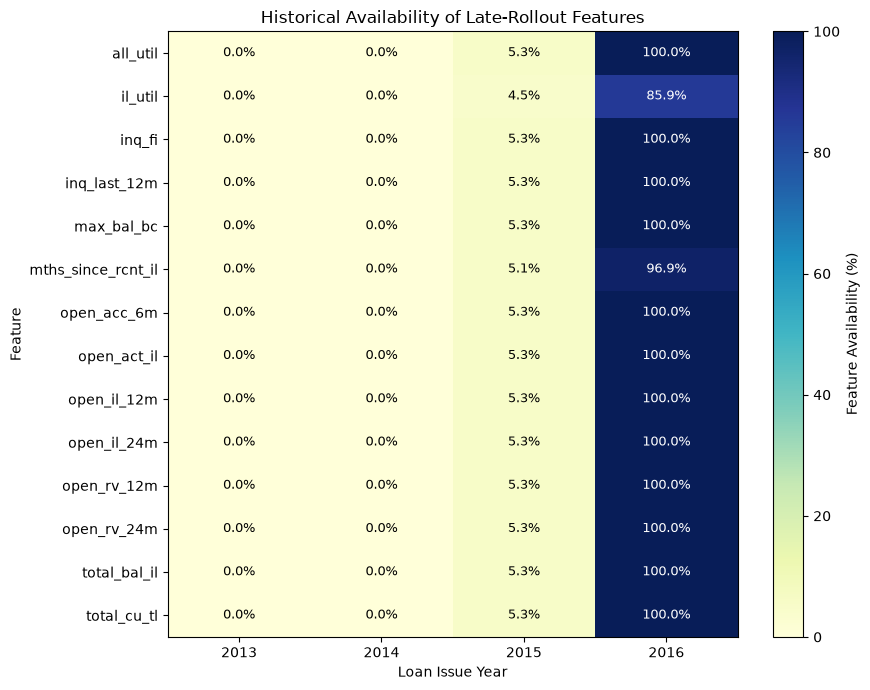

Figure saved: d:\ML_Projects\P2P-Lending-Default-Prediction\reports\eda\figures\01_feature_availability_heatmap.png


In [12]:


# 01.5.2 — Feature availability visualization

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

FIGURE_DIR = ROOT / "reports" / "eda" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

features = sorted(late_rollout)
years = [2013, 2014, 2015, 2016]

coverage = year_coverage.loc[features, years].astype(float)

fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(
    coverage.to_numpy(),
    aspect="auto",
    cmap="YlGnBu",
    vmin=0,
    vmax=100
)

ax.set_xticks(range(len(years)))
ax.set_xticklabels(years)

ax.set_yticks(range(len(features)))
ax.set_yticklabels(features)

for i in range(len(features)):
    for j in range(len(years)):
        value = coverage.iloc[i, j]

        ax.text(
            j, i,
            f"{value:.1f}%",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if value > 65 else "black"
        )

fig.colorbar(
    im,
    ax=ax,
    label="Feature Availability (%)"
)

ax.set_title(
    "Historical Availability of Late-Rollout Features"
)
ax.set_xlabel("Loan Issue Year")
ax.set_ylabel("Feature")

plt.tight_layout()

figure_path = FIGURE_DIR / "01_feature_availability_heatmap.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", figure_path)



### 01.5.3 — Delinquency History and Missingness

Four delinquency-history features exhibit substantial missingness despite being available throughout 2013–2016.

We investigate their missingness patterns and relationships with `delinq_2yrs` to determine whether missing values may reflect the absence of recorded credit events.

Missingness is not automatically treated as a data error. Feature retention depends on availability, financial meaning, and usefulness for the primary model.


In [13]:
event_features = [
    "mths_since_last_delinq",
    "mths_since_last_major_derog",
    "mths_since_recent_bc_dlq",
    "mths_since_recent_revol_delinq"
]

recent_delinq = (
    pl.col("delinq_2yrs")
    .cast(pl.Float64, strict=False)
    .gt(0)
    .fill_null(False)
)

# A. Missingness and relationship to recent delinquency
expr = [
    recent_delinq.sum().alias("recent_delinq_rows")
]

for col in event_features:
    x = pl.col(col).cast(pl.Float64, strict=False)

    expr.extend([
        x.is_null().sum().alias(f"{col}__missing"),
        x.median().alias(f"{col}__median"),
        x.min().alias(f"{col}__min"),
        x.max().alias(f"{col}__max"),
        (x < 0).fill_null(False).sum().alias(f"{col}__negative"),
        (
            recent_delinq & x.is_null()
        ).sum().alias(f"{col}__recent_missing")
    ])

result = df.select(expr).collect().row(0, named=True)

recent_total = result["recent_delinq_rows"]

rows = []

for col in event_features:
    rows.append({
        "feature": col,
        "missing_pct": round(
            100 * result[f"{col}__missing"] / n_rows, 2
        ),
        "median_months_observed": result[f"{col}__median"],
        "min": result[f"{col}__min"],
        "max": result[f"{col}__max"],
        "negative_values": result[f"{col}__negative"],
        "missing_among_recent_delinq_pct": round(
            100 * result[f"{col}__recent_missing"]
            / recent_total, 2
        ) if recent_total else None
    })

event_summary = pd.DataFrame(rows)

print("A. DELINQUENCY-RECENCY SUMMARY")
print("Borrowers with delinq_2yrs > 0:", recent_total)
display(event_summary)


# B. Check whether missingness overlaps between features
presence = [
    pl.col(c)
    .cast(pl.Float64, strict=False)
    .is_not_null()
    .alias(c)
    for c in event_features
]

patterns = (
    df.select(presence)
    .group_by(event_features)
    .agg(pl.len().alias("loans"))
    .sort("loans", descending=True)
    .collect()
    .to_pandas()
)

for col in event_features:
    patterns[col] = patterns[col].map({
        True: "Present",
        False: "Missing"
    })

patterns["cohort_pct"] = (
    100 * patterns["loans"] / n_rows
).round(2)

print("\nB. MISSINGNESS COMBINATIONS")
display(patterns)

A. DELINQUENCY-RECENCY SUMMARY
Borrowers with delinq_2yrs > 0: 178860


,feature,missing_pct,median_months_observed,min,max,negative_values,missing_among_recent_delinq_pct
0,mths_since_last_delinq,48.72,30.0,0.0,192.0,0,1.36
1,mths_since_last_major_derog,71.41,43.0,0.0,192.0,0,49.64
2,mths_since_recent_bc_dlq,74.26,38.0,0.0,189.0,0,45.39
3,mths_since_recent_revol_delinq,64.16,32.0,0.0,197.0,0,23.09



B. MISSINGNESS COMBINATIONS


,mths_since_last_delinq,mths_since_last_major_derog,mths_since_recent_bc_dlq,mths_since_recent_revol_delinq,loans,cohort_pct
0,Missing,Missing,Missing,Missing,413187,47.52
1,Present,Present,Present,Present,132515,15.24
2,Present,Missing,Present,Present,90885,10.45
3,Present,Present,Missing,Missing,72180,8.30
4,Present,Missing,Missing,Missing,62510,7.19
5,Present,Missing,Missing,Present,54182,6.23
6,Present,Present,Missing,Present,33582,3.86
7,Missing,Present,Missing,Missing,9896,1.14
8,Missing,Present,Present,Present,287,0.03
9,Missing,Present,Missing,Present,116,0.01


In [14]:
exclude_sparse = {
    "mths_since_last_major_derog",
    "mths_since_recent_bc_dlq",
    "mths_since_recent_revol_delinq",
}

feature_inventory.loc[
    feature_inventory["feature"].isin(exclude_sparse),
    "availability_decision"
] = "EXCLUDE_SPARSE_EVENT_HISTORY"

feature_inventory.loc[
    feature_inventory["feature"] == "mths_since_last_delinq",
    "availability_decision"
] = "CONTINUE_EDA"

numeric_next = feature_inventory.loc[
    (feature_inventory["data_group"] == "NUMERICAL")
    & (feature_inventory["eligibility"] == "EDA_CANDIDATE")
    & ~feature_inventory["availability_decision"].isin([
        "EXCLUDE_LATE_ROLLOUT",
        "EXCLUDE_SPARSE_EVENT_HISTORY"
    ]),
    "feature"
].tolist()

print("Numerical candidates remaining:", len(numeric_next))
assert len(numeric_next) == 53

Numerical candidates remaining: 53



### 01.5.4 — Final Availability Decisions

The investigation found that delinquency-history missingness is not uniform across features.

We retain `mths_since_last_delinq` for further analysis because it provides relevant credit-history information, despite substantial missingness.

Three additional sparse delinquency-history features are excluded from the primary candidate set:

- `mths_since_last_major_derog`
- `mths_since_recent_bc_dlq`
- `mths_since_recent_revol_delinq`

After excluding 14 late-rollout features and these three sparse features, **53 numerical candidates remain** for further EDA.

These decisions do not modify the original dataset.



## 01.6 — Numerical Distributions and Data Quality

We examine the distributions, central tendencies, and extreme values of the retained numerical features.

The analysis focuses on:

- Loan amount, annual income, and debt-to-income ratio.
- Differences between mean and median.
- Extreme observations and potential data-quality issues.
- Skewness and the suitability of robust imputation.
- Relationships between selected financial characteristics and loan default.

Extreme values are investigated rather than automatically removed. Outlier-treatment decisions are evaluated separately using validation experiments.


In [15]:
features = ["loan_amnt", "annual_inc", "dti"]

expressions = []

for col in features:
    x = pl.col(col).cast(pl.Float64, strict=False)

    expressions.extend([
        x.min().alias(f"{col}_min"),
        x.median().alias(f"{col}_median"),
        x.mean().alias(f"{col}_mean"),
        x.quantile(0.99).alias(f"{col}_p99"),
        x.max().alias(f"{col}_max"),
    ])

result = df.select(expressions).collect().row(0, named=True)

summary = pd.DataFrame([
    {
        "feature": col,
        **{
            stat: result[f"{col}_{stat}"]
            for stat in ["min", "median", "mean", "p99", "max"]
        }
    }
    for col in features
])

display(summary.round(2))

,feature,min,median,mean,p99,max
0,loan_amnt,1000.0,10000.00,12734.50,35000.00,40000.0
1,annual_inc,0.0,62000.00,74603.00,260000.00,9573072.0
2,dti,-1.0,17.53,18.14,38.01,999.0


In [ ]:
# 01.6 — Numerical summary of retained candidates

excluded = {
    # Historical rollout
    "open_acc_6m", "open_act_il",
    "open_il_12m", "open_il_24m",
    "mths_since_rcnt_il", "total_bal_il",
    "il_util", "open_rv_12m", "open_rv_24m",
    "max_bal_bc", "all_util", "inq_fi",
    "total_cu_tl", "inq_last_12m",

    # Sparse delinquency history
    "mths_since_last_major_derog",
    "mths_since_recent_bc_dlq",
    "mths_since_recent_revol_delinq",
}

numeric_cols = feature_inventory.loc[
    (feature_inventory["data_group"] == "NUMERICAL")
    & (feature_inventory["eligibility"] == "EDA_CANDIDATE")
    & (~feature_inventory["feature"].isin(excluded)),
    "feature"
].tolist()

print("Numerical features:", len(numeric_cols))

expressions = []

for col in numeric_cols:
    x = (
        pl.col(col)
        .cast(pl.String)
        .str.strip_chars()
        .str.replace_all("%", "")
        .cast(pl.Float64, strict=False)
    )

    expressions.extend([
        x.count().alias(f"{col}_count"),
        x.min().alias(f"{col}_min"),
        x.median().alias(f"{col}_median"),
        x.mean().alias(f"{col}_mean"),
        x.quantile(0.99).alias(f"{col}_p99"),
        x.max().alias(f"{col}_max"),
    ])

result = df.select(expressions).collect().row(0, named=True)

numeric_summary = pd.DataFrame([
    {
        "feature": col,
        "valid_pct": 100 * result[f"{col}_count"] / n_rows,
        "min": result[f"{col}_min"],
        "median": result[f"{col}_median"],
        "mean": result[f"{col}_mean"],
        "p99": result[f"{col}_p99"],
        "max": result[f"{col}_max"],
    }
    for col in numeric_cols
])

display(numeric_summary.round(2))

Numerical features: 53


,feature,valid_pct,min,median,mean,p99,max
0,loan_amnt,100.00,1000.0,10000.00,12734.50,35000.00,40000.0
1,annual_inc,100.00,0.0,62000.00,74603.00,260000.00,9573072.0
2,dti,100.00,-1.0,17.53,18.14,38.01,999.0
3,delinq_2yrs,100.00,0.0,0.00,0.35,4.00,30.0
4,fico_range_low,100.00,660.0,685.00,694.13,800.00,845.0
5,fico_range_high,100.00,664.0,689.00,698.13,804.00,850.0
6,inq_last_6mths,100.00,0.0,0.00,0.63,4.00,6.0
7,mths_since_last_delinq,51.28,0.0,30.00,33.77,80.00,192.0
8,open_acc,100.00,0.0,10.00,11.50,29.00,86.0
9,pub_rec,100.00,0.0,0.00,0.24,3.00,86.0


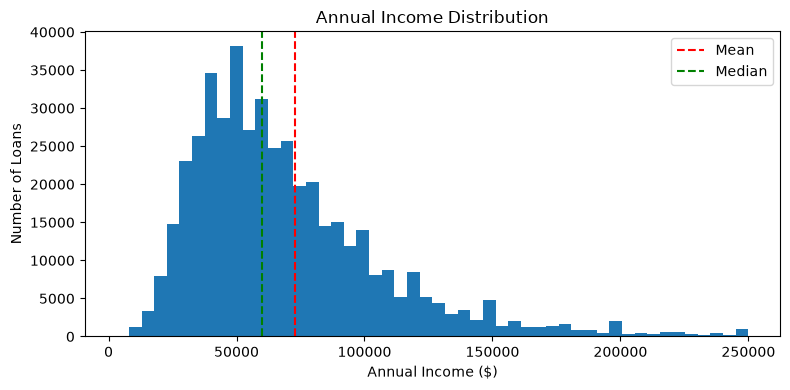

Skewness: 39.58


In [26]:
# Annual income distribution — training data

import matplotlib.pyplot as plt
import polars as pl
from datetime import date

income = (
    df.filter(pl.col("issue_date") < date(2015, 10, 1))
    .select(pl.col("annual_inc").cast(pl.Float64))
    .collect()
    .to_series()
    .to_pandas()
)

fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(income[income <= income.quantile(0.99)], bins=50)

ax.axvline(income.mean(), color="red", linestyle="--", label="Mean")
ax.axvline(income.median(), color="green", linestyle="--", label="Median")

ax.set(
    title="Annual Income Distribution",
    xlabel="Annual Income ($)",
    ylabel="Number of Loans"
)
ax.legend()

fig.tight_layout()

path = ROOT / "reports/eda/figures/02_annual_income_distribution.png"
path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(path, dpi=300)

plt.show()

print("Skewness:", round(income.skew(), 2))


### 01.6.1 — Annual Income Distribution: Findings

Annual income is strongly right-skewed, with a relatively small number of exceptionally high values increasing the mean above the median.

For visualization, values above the 99th percentile are hidden to improve readability; they remain in the original dataset.

This supports the use of median imputation as a robust treatment for missing numerical values, although the final preprocessing decision also considers missingness patterns and feature meaning.


In [ ]:
# 01.6 — Investigate suspicious numerical values

dti = pl.col("dti").cast(pl.Float64, strict=False)
inc = pl.col("annual_inc").cast(pl.Float64, strict=False)

revol = (
    pl.col("revol_util")
    .str.replace_all("%", "")
    .cast(pl.Float64, strict=False)
)

bc = pl.col("bc_util").cast(pl.Float64, strict=False)

coll = pl.col("tot_coll_amt").cast(pl.Float64, strict=False)
rev_limit = pl.col("total_rev_hi_lim").cast(pl.Float64, strict=False)
credit_limit = pl.col("tot_hi_cred_lim").cast(pl.Float64, strict=False)

checks = {
    "Negative DTI": dti < 0,
    "DTI >= 100": dti >= 100,
    "DTI exactly 999": dti == 999,
    "Zero annual income": inc == 0,
    "Income above $1 million": inc > 1_000_000,
    "Revolving utilization > 100%": revol > 100,
    "Revolving utilization > 200%": revol > 200,
    "Bankcard utilization > 100%": bc > 100,
    "Collection amount > $1 million": coll > 1_000_000,
    "Revolving credit limit = 9,999,999": rev_limit == 9_999_999,
    "Total credit limit = 9,999,999": credit_limit == 9_999_999,
}

result = df.select([
    condition.fill_null(False).sum().alias(name)
    for name, condition in checks.items()
]).collect().row(0, named=True)

anomaly_summary = pd.DataFrame({
    "check": list(result),
    "rows": list(result.values())
})

anomaly_summary["pct_of_cohort"] = (
    100 * anomaly_summary["rows"] / n_rows
).round(4)

display(anomaly_summary)

,check,rows,pct_of_cohort
0,Negative DTI,1,0.0001
1,DTI >= 100,91,0.0105
2,DTI exactly 999,6,0.0007
3,Zero annual income,38,0.0044
4,Income above $1 million,192,0.0221
5,Revolving utilization > 100%,3391,0.3900
6,Revolving utilization > 200%,1,0.0001
7,Bankcard utilization > 100%,14381,1.6539
8,Collection amount > $1 million,1,0.0001
9,"Revolving credit limit = 9,999,999",3,0.0003



### 01.6.2 — Numerical Data Quality: Findings

The dataset contains several unusual numerical observations:

- 1 record with negative DTI.
- 6 records with DTI equal to 999.
- 192 loans with annual income exceeding $1 million.
- 3,391 records with revolving utilization above 100%.
- 14,381 records with bankcard utilization above 100%.

These values require careful interpretation. High income, large credit balances, and utilization exceeding 100% are not necessarily errors.

Invalid values are handled during preprocessing where appropriate. Valid extreme observations are retained rather than automatically removed.

A separate outlier-removal experiment showed a slight decline in validation performance. Therefore, the original observations are retained for the final model.



### 01.6.3 — Numerical Feature Correlation and Redundancy

We use Spearman rank correlation to identify strongly related numerical features.

Spearman correlation is suitable for examining monotonic relationships without assuming linearity or normally distributed features.

The analysis is performed on a sample of approximately 43,500 loans. Highly correlated feature pairs are investigated for redundancy rather than automatically removed.

Selected feature pairs are also compared directly to determine whether they contain nearly identical information.


In [27]:
import numpy as np

# Sample every 20th loan across the full cohort (~43,500 rows)
sample = (
    df.with_row_index("_row")
    .filter(pl.col("_row") % 20 == 0)
    .select([
        pl.col(c)
        .cast(pl.String)
        .str.strip_chars()
        .str.replace_all("%", "")
        .cast(pl.Float64, strict=False)
        .alias(c)
        for c in numeric_cols
    ])
    .collect()
    .to_pandas()
)

# Spearman correlation for all 53 features
corr = sample.corr(method="spearman")

# Extract each unique feature pair
upper = corr.where(
    np.triu(np.ones(corr.shape, dtype=bool), k=1)
)

pairs = (
    upper.stack()
    .reset_index()
)

pairs.columns = ["feature_1", "feature_2", "spearman"]

pairs["abs_corr"] = pairs["spearman"].abs()

pairs = pairs.sort_values("abs_corr", ascending=False)

print("Pairs with |correlation| >= 0.85:",
      (pairs["abs_corr"] >= 0.85).sum())

display(pairs.head(25).round(4))

Pairs with |correlation| >= 0.85: 9


,feature_1,feature_2,spearman,abs_corr
202,fico_range_low,fico_range_high,1.0000,1.0000
419,open_acc,num_sats,0.9982,0.9982
1193,num_actv_rev_tl,num_rev_tl_bal_gt_0,0.9900,0.9900
744,tot_cur_bal,tot_hi_cred_lim,0.9719,0.9719
714,tot_cur_bal,avg_cur_bal,0.9307,0.9307
846,avg_cur_bal,tot_hi_cred_lim,0.8826,0.8826
781,total_rev_hi_lim,total_bc_limit,0.8667,0.8667
906,bc_util,percent_bc_gt_75,0.8576,0.8576
1376,total_bal_ex_mort,total_il_high_credit_limit,0.8546,0.8546
1169,num_actv_bc_tl,num_bc_sats,0.8433,0.8433


In [19]:
checks = [
    ("FICO range width", "fico_range_high", "fico_range_low"),
    ("Open account counts", "open_acc", "num_sats"),
    ("Active revolving counts", "num_actv_rev_tl", "num_rev_tl_bal_gt_0"),
]

results = []

for name, a, b in checks:
    diff = (
        pl.col(a).cast(pl.Float64, strict=False)
        - pl.col(b).cast(pl.Float64, strict=False)
    )

    stats = df.select(
        (diff == 0).fill_null(False).mean().alias("equal_fraction"),
        diff.median().alias("median_difference"),
        diff.min().alias("minimum_difference"),
        diff.max().alias("maximum_difference"),
    ).collect().row(0, named=True)

    results.append({
        "pair": name,
        "equal_pct": 100 * stats["equal_fraction"],
        "median_diff": stats["median_difference"],
        "min_diff": stats["minimum_difference"],
        "max_diff": stats["maximum_difference"],
    })

display(pd.DataFrame(results).round(2))

,pair,equal_pct,median_diff,min_diff,max_diff
0,FICO range width,0.00,4.0,4.0,5.0
1,Open account counts,96.08,0.0,0.0,14.0
2,Active revolving counts,94.98,0.0,-12.0,32.0



### 01.6.4 — Correlation and Redundancy Findings

Several numerical features exhibit strong correlations.

Notable examples include:

- `fico_range_low` and `fico_range_high`: nearly perfectly correlated.
- `open_acc` and `num_sats`: approximately 99.82% Spearman correlation.
- `num_actv_rev_tl` and `num_rev_tl_bal_gt_0`: approximately 99.01% Spearman correlation.

Direct comparisons further support the redundancy of these feature pairs.

We exclude `fico_range_high`, `num_sats`, and `num_rev_tl_bal_gt_0` from the final candidate set, retaining their corresponding alternative features.

Other correlated variables are not automatically removed because they may contain complementary information useful for nonlinear models.



## 01.7 — Categorical Feature Analysis

We examine categorical features to understand their distributions, cardinality, and missingness.

The analysis focuses on employment length, home ownership, loan purpose, and geographical information.

High-cardinality features such as `zip_code` require additional consideration because they may introduce unnecessary complexity or geographic proxies.

Categorical features are not excluded solely because they contain many categories. Final decisions also depend on prediction-time availability and feature relevance.


In [20]:
categorical_cols = [
    "addr_state", "application_type", "emp_length",
    "home_ownership", "purpose", "verification_status",
    "zip_code"
]

expr = []

for col in categorical_cols:
    x = pl.col(col).cast(pl.String).str.strip_chars()
    valid = x.is_not_null() & (x != "")

    expr.extend([
        x.filter(valid).n_unique().alias(f"{col}_unique"),
        (~valid).sum().alias(f"{col}_missing"),
    ])

result = df.select(expr).collect().row(0, named=True)

cat_summary = pd.DataFrame([
    {
        "feature": col,
        "unique_categories": result[f"{col}_unique"],
        "missing_pct": round(
            100 * result[f"{col}_missing"] / n_rows, 2
        ),
    }
    for col in categorical_cols
])

display(cat_summary)

,feature,unique_categories,missing_pct
0,addr_state,51,0.00
1,application_type,2,0.00
2,emp_length,11,6.57
3,home_ownership,4,0.00
4,purpose,14,0.00
5,verification_status,3,0.00
6,zip_code,927,0.00


In [28]:
# 01.7 — Category frequencies

categorical_cols = [
    "addr_state",
    "emp_length",
    "home_ownership",
    "purpose",
]

for col in categorical_cols:

    counts = (
        df.select(
            pl.col(col)
            .cast(pl.String)
            .str.strip_chars()
            .fill_null("MISSING")
            .replace("", "MISSING")
            .alias("category")
        )
        .group_by("category")
        .agg(pl.len().alias("count"))
        .sort("count", descending=True)
        .collect()
        .to_pandas()
    )

    counts["pct"] = (
        100 * counts["count"] / n_rows
    ).round(2)

    print(f"\n{col} — {len(counts)} categories")
    display(counts.head(20))


addr_state — 51 categories


,category,count,pct
0,CA,127084,14.62
1,NY,73148,8.41
2,TX,72342,8.32
3,FL,62821,7.22
4,IL,35494,4.08
5,NJ,31566,3.63
6,PA,28576,3.29
7,OH,28520,3.28
8,GA,28210,3.24
9,NC,23427,2.69



emp_length — 12 categories


,category,count,pct
0,10+ years,279523,32.15
1,2 years,79480,9.14
2,3 years,70597,8.12
3,< 1 year,69030,7.94
4,1 year,58208,6.69
5,MISSING,57102,6.57
6,5 years,53184,6.12
7,4 years,51079,5.87
8,8 years,41021,4.72
9,6 years,39485,4.54



home_ownership — 4 categories


,category,count,pct
0,MORTGAGE,404220,46.49
1,RENT,367160,42.22
2,OWN,98068,11.28
3,ANY,92,0.01



purpose — 14 categories


,category,count,pct
0,debt_consolidation,491439,56.52
1,credit_card,206056,23.70
2,home_improvement,54665,6.29
3,other,52552,6.04
4,major_purchase,18322,2.11
5,medical,10386,1.19
6,car,9251,1.06
7,small_business,8883,1.02
8,vacation,6719,0.77
9,moving,6631,0.76



### 01.7.1 — Categorical Analysis: Findings

The categorical analysis identified the following characteristics:

- **Loan purpose:** Debt consolidation (56.52%) and credit-card refinancing (23.70%) account for most loans.
- **Home ownership:** Mortgage (46.49%) and rent (42.22%) are the most common categories.
- **Employment length:** Approximately 6.57% of records have missing employment duration.
- **Geography:** `addr_state` contains 51 categories, while `zip_code` contains 927 categories.
- **Application type:** Individual applications account for approximately 99.37% of the cohort.

These findings support appropriate categorical encoding and missing-value handling.

`zip_code` is excluded from the primary model due to its high cardinality and potential geographic-proxy concerns. Other categorical features are reviewed further during preprocessing.



## 01.8 — Feature Selection and Inventory Export

The EDA findings are consolidated into a feature inventory documenting each variable's eligibility for modeling.

Feature decisions consider:

- Target leakage and prediction-time availability.
- Historical feature coverage.
- Missingness and data quality.
- Strongly redundant features.
- High-cardinality and geographic-proxy concerns.

The inventory retains **50 numerical candidates** and **6 categorical candidates requiring final review**.

The results are exported to `reports/eda/01_feature_manifest_draft.csv` for use in Notebook 02.

No original data is modified.


In [22]:

# 01.8 — Export feature decisions for preprocessing

from pathlib import Path
import pandas as pd
from IPython.display import display

ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)
REPORTS = ROOT / "reports" / "eda"
REPORTS.mkdir(parents=True, exist_ok=True)

manifest = feature_inventory.copy()

# Preserve the existing EDA classifications
manifest["model_status"] = manifest["eligibility"]

eligible = manifest["eligibility"].eq("EDA_CANDIDATE")

# Initial numerical and categorical candidates
manifest.loc[
    eligible & manifest["data_group"].eq("NUMERICAL"),
    "model_status"
] = "CANDIDATE_NUMERIC"

manifest.loc[
    eligible & manifest["data_group"].eq("CATEGORICAL"),
    "model_status"
] = "CANDIDATE_CATEGORICAL"

# Decisions already established in EDA
for old_status in [
    "EXCLUDE_LATE_ROLLOUT",
    "EXCLUDE_SPARSE_EVENT_HISTORY",
]:
    mask = manifest["availability_decision"].eq(old_status)
    manifest.loc[mask, "model_status"] = old_status

redundant = {
    "fico_range_high",
    "num_sats",
    "num_rev_tl_bal_gt_0",
}

manifest.loc[
    manifest["feature"].isin(redundant),
    "model_status"
] = "EXCLUDE_REDUNDANT"

manifest.loc[
    manifest["feature"].eq("zip_code"),
    "model_status"
] = "EXCLUDE_GEOGRAPHIC_PROXY"

# Unresolved prediction-time decisions
reviews = {
    "addr_state": "REVIEW_GEOGRAPHY",
    "application_type": "REVIEW_HISTORICAL_AVAILABILITY",
    "verification_status": "HOLD_VERIFICATION",
    "earliest_cr_line": "REVIEW_CREDIT_AGE_ENGINEERING",
    "emp_title": "HOLD_TEXT",
    "title": "HOLD_TEXT",
}

for feature, status in reviews.items():
    manifest.loc[
        manifest["feature"].eq(feature),
        "model_status"
    ] = status

# Hold lender-generated information separately
manifest.loc[
    manifest["eligibility"].eq("REVIEW_LENDER_INFO"),
    "model_status"
] = "HOLD_LENDER_INFO"

# Verify the agreed candidate counts
n_numeric = manifest["model_status"].eq("CANDIDATE_NUMERIC").sum()

cat_statuses = {
    "CANDIDATE_CATEGORICAL",
    "REVIEW_GEOGRAPHY",
    "REVIEW_HISTORICAL_AVAILABILITY",
    "HOLD_VERIFICATION",
}

n_categorical = manifest["model_status"].isin(cat_statuses).sum()

assert n_numeric == 50, f"Expected 50 numeric, found {n_numeric}"
assert n_categorical == 6, f"Expected 6 categorical, found {n_categorical}"
assert manifest["feature"].is_unique

# Save complete 146-column decision register
output = REPORTS / "01_feature_manifest_draft.csv"

manifest.to_csv(output, index=False)

print("Saved:", output)
print("Numerical candidates:", n_numeric)
print("Categorical candidates:", n_categorical)

display(
    manifest["model_status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="features")
)


Saved: d:\ML_Projects\P2P-Lending-Default-Prediction\reports\eda\01_feature_manifest_draft.csv
Numerical candidates: 50
Categorical candidates: 6


,status,features
0,CANDIDATE_NUMERIC,50
1,EXCLUDE_LEAKAGE,31
2,EXCLUDE_LATE_ROLLOUT,14
3,SKIP_ALL_MISSING,13
4,HOLD_LENDER_INFO,7
5,METADATA,6
6,SKIP_HIGH_MISSING,4
7,EXCLUDE_IDENTIFIER,3
8,EXCLUDE_REDUNDANT,3
9,CANDIDATE_CATEGORICAL,3



### 01.9 — Numerical Skewness Analysis

We calculate skewness for the selected numerical features using the 2013–2015 training cohort.

Strongly skewed distributions can make mean imputation sensitive to extreme values. Median imputation provides a robust and consistent alternative.

Skewness is supporting evidence, not proof that median imputation produces the best predictive performance. Missingness and feature meaning are also considered.


In [23]:

from datetime import date
import numpy as np
import pandas as pd
import polars as pl
from IPython.display import display

# Use the final EDA feature manifest
skew_features = manifest.loc[
    manifest["model_status"].eq("CANDIDATE_NUMERIC"),
    "feature"
].tolist()

# Included later in the 55-feature model
skew_features += ["int_rate"]
skew_features = list(dict.fromkeys(skew_features))

train_lf = df.filter(
    (pl.col("issue_date") >= date(2013, 1, 1))
    & (pl.col("issue_date") < date(2015, 10, 1))
)

train_count = train_lf.select(pl.len()).collect().item()
assert train_count == 457355

rows = []

# Process features in batches to control memory
for start in range(0, len(skew_features), 8):
    batch = skew_features[start:start + 8]
    expressions = []

    for col in batch:
        value = (
            pl.col(col)
            .cast(pl.String)
            .str.strip_chars()
            .str.replace_all("%", "")
            .cast(pl.Float64, strict=False)
        )

        value = pl.when(value.is_finite()).then(value).otherwise(None)

        if col == "dti":
            value = pl.when(value >= 0).then(value).otherwise(None)

        expressions.extend([
            value.count().alias(f"{col}__valid"),
            value.mean().alias(f"{col}__mean"),
            value.median().alias(f"{col}__median"),
            value.skew().alias(f"{col}__skew"),
            value.quantile(0.99).alias(f"{col}__p99"),
            value.max().alias(f"{col}__max"),
        ])

    result = train_lf.select(expressions).collect().row(
        0, named=True
    )

    for col in batch:
        skew = result[f"{col}__skew"]

        rows.append({
            "feature": col,
            "missing_pct": round(
                100 * (1 - result[f"{col}__valid"] / train_count), 2
            ),
            "mean": result[f"{col}__mean"],
            "median": result[f"{col}__median"],
            "skewness": skew,
            "p99": result[f"{col}__p99"],
            "maximum": result[f"{col}__max"],
        })

skew_report = pd.DataFrame(rows)

def skew_category(value):
    if pd.isna(value):
        return "Undefined"
    if value < -1:
        return "Strong left skew"
    if value > 1:
        return "Strong right skew"
    if abs(value) >= 0.5:
        return "Moderate skew"
    return "Approximately symmetric"

skew_report["distribution"] = (
    skew_report["skewness"].apply(skew_category)
)

skew_report["absolute_skew"] = (
    skew_report["skewness"].abs()
)

skew_report = skew_report.sort_values(
    "absolute_skew", ascending=False
)

print("Training rows:", train_count)
print("Features analyzed:", len(skew_report))

print("\nDistribution classification:")
display(skew_report["distribution"].value_counts())

print("\nMost skewed features:")
display(skew_report.head(20).round(3))

print("\nSkewness of features requiring imputation:")
display(
    skew_report.loc[
        skew_report["missing_pct"] > 0,
        [
            "feature",
            "missing_pct",
            "mean",
            "median",
            "skewness",
            "distribution",
        ],
    ].round(3)
)

output = ROOT / "reports/eda/01_training_skewness.csv"
skew_report.to_csv(output, index=False)

print("\nSaved:", output)


Training rows: 457355
Features analyzed: 51

Distribution classification:


distribution
Strong right skew          41
Approximately symmetric     7
Moderate skew               2
Strong left skew            1
Name: count, dtype: int64


Most skewed features:


,feature,missing_pct,mean,median,skewness,p99,maximum,distribution,absolute_skew
14,tot_coll_amt,0.00,241.966,0.0,656.804,4829.0,9152545.0,Strong right skew,656.804
16,total_rev_hi_lim,0.00,30114.948,21700.0,100.263,147160.0,9999999.0,Strong right skew,100.263
22,delinq_amnt,0.00,11.765,0.0,82.508,0.0,94521.0,Strong right skew,82.508
38,num_tl_120dpd_2m,3.44,0.001,0.0,51.572,0.0,6.0,Strong right skew,51.572
1,annual_inc,0.00,72661.168,60000.0,39.579,250000.0,8900060.0,Strong right skew,39.579
45,tax_liens,0.00,0.054,0.0,31.715,2.0,63.0,Strong right skew,31.715
13,acc_now_delinq,0.00,0.005,0.0,27.738,0.0,14.0,Strong right skew,27.738
9,revol_bal,0.00,15679.361,10744.0,21.742,88334.0,2904836.0,Strong right skew,21.742
39,num_tl_30dpd,0.00,0.003,0.0,21.637,0.0,4.0,Strong right skew,21.637
12,collections_12_mths_ex_med,0.00,0.016,0.0,20.878,1.0,20.0,Strong right skew,20.878



Skewness of features requiring imputation:


,feature,missing_pct,mean,median,skewness,distribution
38,num_tl_120dpd_2m,3.44,0.001,0.0,51.572,Strong right skew
19,bc_open_to_buy,0.98,8809.444,3767.0,3.950,Strong right skew
28,mths_since_recent_bc,0.91,24.473,14.0,3.269,Strong right skew
42,pct_tl_nvr_dlq,0.02,94.129,98.0,-2.100,Strong left skew
29,mths_since_recent_inq,10.46,6.938,5.0,0.910,Moderate skew
20,bc_util,1.05,63.021,66.9,-0.470,Approximately symmetric
6,mths_since_last_delinq,50.22,33.991,31.0,0.466,Approximately symmetric
23,mo_sin_old_il_acct,3.77,124.952,128.0,0.371,Approximately symmetric
43,percent_bc_gt_75,1.03,48.627,50.0,0.077,Approximately symmetric
10,revol_util,0.05,54.288,54.8,-0.013,Approximately symmetric



Saved: d:\ML_Projects\P2P-Lending-Default-Prediction\reports\eda\01_training_skewness.csv



### 01.9.1 — Skewness Analysis: Findings

Of the 51 numerical features examined, 41 exhibit strong right skewness, 1 exhibits strong left skewness, 2 show moderate skewness, and 7 are approximately symmetric.

Financial variables such as `annual_inc`, `revol_bal`, and `total_rev_hi_lim` have particularly long right tails.

These results support the use of robust numerical preprocessing. Median imputation is preferred over mean imputation because it is less sensitive to extreme observations.

However, skewness alone does not determine the optimal imputation strategy. Missingness patterns and feature meaning are also considered.

No transformation or removal is performed during this analysis.



### 01.10 — Outlier Investigation

We examine extreme numerical values using the interquartile range (IQR) rule.

IQR flags are statistical observations, not automatic data errors. We retain all records at this stage and measure how many borrowers would be affected by possible removal.

All thresholds are calculated from training data. No test observations are used to determine treatment.


In [24]:

outlier_features = [
    "loan_amnt",
    "annual_inc",
    "dti",
    "revol_bal",
    "revol_util",
    "tot_cur_bal",
    "total_rev_hi_lim",
    "bc_util",
    "avg_cur_bal",
    "int_rate",
]

expressions = []

for col in outlier_features:
    value = (
        pl.col(col)
        .cast(pl.String)
        .str.strip_chars()
        .str.replace_all("%", "")
        .cast(pl.Float64, strict=False)
    )

    value = pl.when(value.is_finite()).then(value).otherwise(None)

    if col == "dti":
        value = pl.when(value >= 0).then(value).otherwise(None)

    expressions.append(value.alias(col))

expressions.append(pl.col("target").cast(pl.Int8))

# Training data only
outlier_df = train_lf.select(expressions).collect().to_pandas()

y_outlier = outlier_df["target"]
combined_flags = np.zeros(len(outlier_df), dtype=bool)

results = []

for col in outlier_features:
    values = outlier_df[col]

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    if pd.isna(iqr) or iqr == 0:
        results.append({
            "feature": col,
            "iqr": iqr,
            "lower_limit": np.nan,
            "upper_limit": np.nan,
            "flagged_rows": 0,
            "flagged_pct": 0.0,
            "default_rate_flagged": np.nan,
            "default_rate_other": y_outlier.mean(),
        })
        continue

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    flags = (
        (values < lower) | (values > upper)
    ).fillna(False)

    combined_flags |= flags.to_numpy()

    results.append({
        "feature": col,
        "iqr": iqr,
        "lower_limit": lower,
        "upper_limit": upper,
        "flagged_rows": int(flags.sum()),
        "flagged_pct": round(flags.mean() * 100, 3),
        "default_rate_flagged": (
            y_outlier[flags].mean() if flags.any() else np.nan
        ),
        "default_rate_other": y_outlier[~flags].mean(),
    })

outlier_report = (
    pd.DataFrame(results)
    .sort_values("flagged_pct", ascending=False)
)

print("Training rows:", len(outlier_df))
print("Overall default rate:", round(y_outlier.mean(), 4))

print("\nPer-feature IQR flags:")
display(outlier_report.round(4))

print("\nCombined IQR flags:")
print("Flagged rows:", int(combined_flags.sum()))
print("Flagged percentage:",
      round(combined_flags.mean() * 100, 2), "%")
print("Retained if all flagged rows removed:",
      int((~combined_flags).sum()))

if combined_flags.any():
    print("Flagged default rate:",
          round(y_outlier[combined_flags].mean(), 4))
    print("Other default rate:",
          round(y_outlier[~combined_flags].mean(), 4))

output = ROOT / "reports/eda/01_training_outliers.csv"
outlier_report.to_csv(output, index=False)

print("\nSaved:", output)


Training rows: 457355
Overall default rate: 0.1393

Per-feature IQR flags:


,feature,iqr,lower_limit,upper_limit,flagged_rows,flagged_pct,default_rate_flagged,default_rate_other
3,revol_bal,12979.00,-13533.500,38382.500,27792,6.077,0.0986,0.1419
6,total_rev_hi_lim,24300.00,-23750.000,73450.000,27771,6.072,0.0774,0.1433
8,avg_cur_bal,14387.00,-18815.500,38732.500,26638,5.824,0.0744,0.1433
1,annual_inc,44500.00,-23750.000,154250.000,21082,4.610,0.0931,0.1415
5,tot_cur_bal,164363.00,-221130.500,436321.500,18783,4.107,0.0766,0.1419
0,loan_amnt,9800.00,-7700.000,31500.000,15482,3.385,0.1417,0.1392
9,int_rate,5.48,0.950,22.870,4223,0.923,0.3194,0.1376
4,revol_util,35.00,-15.400,124.600,39,0.009,0.2821,0.1392
7,bc_util,43.10,-21.350,151.050,34,0.007,0.1471,0.1393
2,dti,12.03,-6.485,41.635,0,0.000,NaN,0.1393



Combined IQR flags:
Flagged rows: 82679
Flagged percentage: 18.08 %
Retained if all flagged rows removed: 374676
Flagged default rate: 0.107
Other default rate: 0.1464

Saved: d:\ML_Projects\P2P-Lending-Default-Prediction\reports\eda\01_training_outliers.csv



### 01.10.1 — Outlier Analysis: Findings

The IQR analysis identified 82,679 training observations (18.08%) with at least one extreme value across the 10 investigated numerical features.

Several financial features, including revolving balance, annual income, and total credit limits, contain substantial upper-tail observations.

These extremes are not necessarily erroneous and may represent valid borrower characteristics.

A subsequent controlled experiment evaluated IQR-based removal using five selected financial features. Validation PR-AUC decreased slightly from **0.29912 to 0.29846**, with similarly small declines in other metrics.

**Decision:** General outlier removal is not adopted because it provided no predictive improvement. The original observations are retained.
